In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import RobustScaler

# Use absolute paths — no more relative path issues
BASE_DIR = Path(r"C:\Projects\cancer-classifier")
RAW_DIR  = BASE_DIR / "data" / "raw"
PROC_DIR = BASE_DIR / "data" / "processed"
FIG_DIR  = BASE_DIR / "outputs" / "figures"

PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Change this line
LABELS = ["BRCA", "LUAD", "KIRC", "LGG", "COAD"]  
print(f"  RAW_DIR  → {RAW_DIR}")
print(f"  PROC_DIR → {PROC_DIR}")
print(f"  FIG_DIR  → {FIG_DIR}")

  RAW_DIR  → C:\Projects\cancer-classifier\data\raw
  PROC_DIR → C:\Projects\cancer-classifier\data\processed
  FIG_DIR  → C:\Projects\cancer-classifier\outputs\figures


In [12]:
frames = []
for label in LABELS:
    df = pd.read_parquet(RAW_DIR / f"{label}_expression.parquet")
    df = df.T                          # flip → samples × genes
    df["cancer_type"] = label
    frames.append(df)

# Use gene intersection (handles GBM's 378 vs 383)
common_genes = list(set.intersection(*[set(f.columns) - {"cancer_type"} for f in frames]))
print(f"Common genes across all studies: {len(common_genes)}")

combined = pd.concat([f[common_genes + ["cancer_type"]] for f in frames], axis=0)
combined.index.name = "sample_id"
combined = combined.reset_index()

print(f"Combined shape: {combined.shape}")
print(f"Class distribution:\n{combined['cancer_type'].value_counts()}")

Common genes across all studies: 340
Combined shape: (792, 342)
Class distribution:
cancer_type
LGG     200
BRCA    199
KIRC    198
LUAD    133
COAD     62
Name: count, dtype: int64


In [18]:
# Diagnose where NaNs are coming from
print("NaN count per cancer type:")
for label in LABELS:
    mask = combined["cancer_type"] == label
    n_nan = combined.loc[mask, gene_cols].isna().sum().sum()
    print(f"  {label}: {n_nan} NaN values")

print(f"\nTotal NaNs: {combined[gene_cols].isna().sum().sum()}")
print(f"Columns with ANY NaN: {combined[gene_cols].isna().any().sum()}")

NaN count per cancer type:
  BRCA: 0 NaN values
  LUAD: 0 NaN values
  KIRC: 0 NaN values
  LGG: 0 NaN values
  COAD: 0 NaN values

Total NaNs: 0
Columns with ANY NaN: 0


In [14]:
gene_cols = common_genes

# Fill NaNs before transform (median per gene is biologically sensible)
combined[gene_cols] = combined[gene_cols].apply(
    lambda col: col.fillna(col.median())
)

X_raw = combined[gene_cols].values.astype(float)
print(f"NaNs after fill: {np.isnan(X_raw).sum()}")
print(f"Before log1p → min: {np.nanmin(X_raw):.1f}, max: {np.nanmax(X_raw):.1f}, mean: {np.nanmean(X_raw):.1f}")

# Clip any negatives to 0 (RSEM shouldn't have negatives but just in case)
X_raw = np.clip(X_raw, 0, None)
combined[gene_cols] = np.log1p(X_raw)

X_log = combined[gene_cols].values
print(f"After  log1p → min: {X_log.min():.2f}, max: {X_log.max():.2f}, mean: {X_log.mean():.2f}")

NaNs after fill: 0
Before log1p → min: 0.0, max: 581293.2, mean: 2060.3
After  log1p → min: 0.00, max: 13.27, mean: 6.50


In [7]:
# Genes with near-zero variance carry no signal and hurt the model
variances  = combined[gene_cols].var()
VAR_THRESH = variances.quantile(0.10)   # drop bottom 10%

high_var_genes = variances[variances > VAR_THRESH].index.tolist()
print(f"Genes before variance filter : {len(gene_cols)}")
print(f"Genes after  variance filter : {len(high_var_genes)}")

combined = combined[["sample_id", "cancer_type"] + high_var_genes]

Genes before variance filter : 378
Genes after  variance filter : 340


In [15]:
# RobustScaler uses median/IQR → less sensitive to outliers than StandardScaler
scaler = RobustScaler()
X = combined[high_var_genes].values
X_scaled = scaler.fit_transform(X)

# Put back into dataframe
df_scaled = pd.DataFrame(X_scaled, columns=high_var_genes)
df_scaled.insert(0, "sample_id",   combined["sample_id"].values)
df_scaled.insert(1, "cancer_type", combined["cancer_type"].values)

print(f"Final dataset shape: {df_scaled.shape}")
print(f"Value range after scaling → min: {X_scaled.min():.2f}, max: {X_scaled.max():.2f}")

Final dataset shape: (792, 342)
Value range after scaling → min: -10.16, max: 18.01


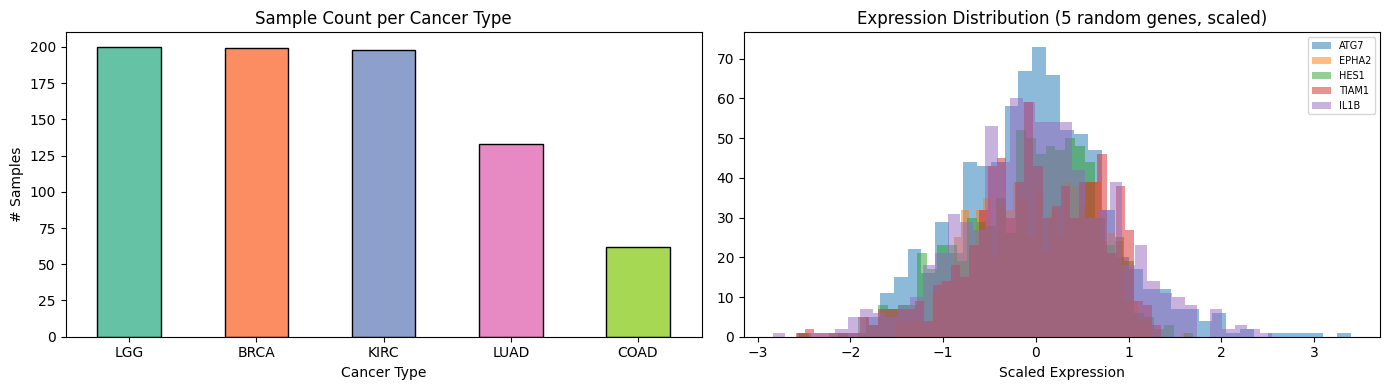

✅ Plot saved!


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Class balance
combined["cancer_type"].value_counts().plot(
    kind="bar", ax=axes[0], color=sns.color_palette("Set2", 5), edgecolor="black"
)
axes[0].set_title("Sample Count per Cancer Type")
axes[0].set_xlabel("Cancer Type")
axes[0].set_ylabel("# Samples")
axes[0].tick_params(axis="x", rotation=0)

# Expression distribution after scaling (sample 5 random genes)
sample_genes = np.random.choice(high_var_genes, 5, replace=False)
for gene in sample_genes:
    axes[1].hist(df_scaled[gene], bins=40, alpha=0.5, label=gene)
axes[1].set_title("Expression Distribution (5 random genes, scaled)")
axes[1].set_xlabel("Scaled Expression")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.savefig(FIG_DIR / "01_preprocessing_overview.png", dpi=150)
plt.show()
print("✅ Plot saved!")

In [19]:
df_scaled.to_parquet(PROC_DIR / "dataset_scaled.parquet")
pd.Series(high_var_genes).to_csv(PROC_DIR / "selected_genes.csv", index=False)

print("✅ Saved:")
print(f"  → data/processed/dataset_scaled.parquet  ({df_scaled.shape})")
print(f"  → data/processed/selected_genes.csv       ({len(high_var_genes)} genes)")

✅ Saved:
  → data/processed/dataset_scaled.parquet  ((792, 342))
  → data/processed/selected_genes.csv       (340 genes)
